# 03 · Stationary profiles and the generalised Riemann problem

For $u_t + (g(x)u^2)_x = 0$ the constant states of the homogeneous theory
are replaced by **stationary profiles**. These are the curves with constant
flux level

$$\theta = G(x,u) = \mathrm{sgn}(u)\,f(x,u),\qquad
  u = U[\theta](x) = \mathrm{sgn}(g)\,\frac{s(\theta)}{\sigma(x)},\quad
  s(\theta)=\mathrm{sgn}\,\theta\sqrt{|\theta|},\ \sigma=\sqrt{|g_\Delta|}.$$

Front tracking discretises θ, not the flux (HetFT; *Failure of uniqueness* §4).
This notebook looks at the profiles, the shock/δ-fan rule, and why one rule
in θ serves both signs of $g$.

In [1]:
# Use the local checkout if present; otherwise install from GitHub (needs the repository to be public).
import sys, subprocess, importlib.util
from pathlib import Path
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/hetfront/__init__.py").is_file()), None)
if local_src is not None:
    sys.path.insert(0, str(local_src))
elif importlib.util.find_spec("hetfront") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/parasuramv/heterogeneous-front-tracking"])
import numpy as np
import matplotlib.pyplot as plt
import hetfront
from hetfront import (HeteroFrontTracker, PeriodicHeteroFrontTracker, MultiplicativeFlux,
                      PiecewiseAffine, trajectory)
from hetfront.visualization import (observe_tracker, plot_spacetime, plot_profile,
                                    plot_heterogeneity, plot_diagnostics, plot_circle, overview)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
print("hetfront", hetfront.__version__, "from", "local checkout" if local_src else "installed package")

hetfront 0.1.0 from local checkout


## Stationary profiles
Each level θ gives one profile. Where $g\to0$ the profile blows up like $|x-z|^{-1/2}$, which is still integrable. A characteristic's speed is $f_u = 2\sigma s$, so **sgn θ is the direction of propagation** whatever the sign of $g$.

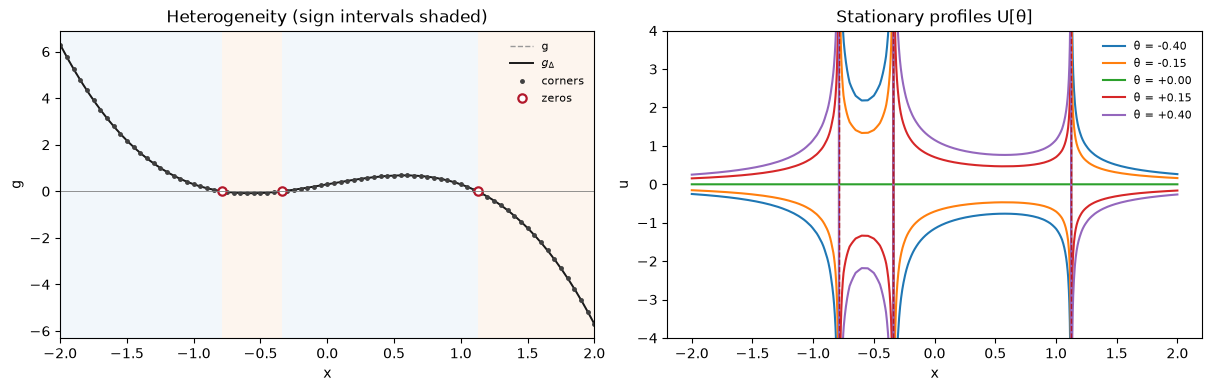

zero of g at [-0.78648254 -0.33893624  1.12541878] ; ∫ near it is finite: ∫_z^{z+0.1} U[0.4] dx = -0.46583329133540413


In [2]:
g = PiecewiseAffine.from_function(lambda x: x * (1 - x**2) + 0.3, np.linspace(-2, 2, 81))
flux = MultiplicativeFlux(g, 0.05)
x = np.linspace(-2, 2, 2001)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
plot_heterogeneity(g, (-2, 2), ax=axes[0], exact=lambda x: x * (1 - x**2) + 0.3)
for k in (-8, -3, 0, 3, 8):
    u = flux.u(np.full(x.shape, k), x)
    axes[1].plot(x, np.where(np.isfinite(u), u, np.nan), label=f"θ = {k * flux.delta:+.2f}")
for z in g.zeros:
    axes[1].axvline(z, color="#b2182b", ls="--", lw=1)
axes[1].set(ylim=(-4, 4), xlabel="x", ylabel="u", title="Stationary profiles U[θ]")
axes[1].legend(fontsize=8, frameon=False)
plt.show()
print("zero of g at", g.zeros, "; ∫ near it is finite: ∫_z^{z+0.1} U[0.4] dx =",
      HeteroFrontTracker(flux, [], [8]).integral(g.zeros[0], g.zeros[0] + 0.1))

## One Riemann rule in θ

On a cell with $g>0$ the flux is convex and $G$ increases in $u$. With
$g<0$ the flux is concave and $G$ decreases in $u$. The two sign flips
cancel, so in both cases

* $\theta_L > \theta_R$ gives an **entropic shock** (HetFT Thm 2.3);
* $\theta_L < \theta_R$ gives a **δ-fan** of unit level steps (HetFT Def. 1).

Below, the same pair of levels is solved where $g>0$ and where $g<0$. In u
the two pictures are mirror images (convex versus concave), but the
θ-rule is identical.

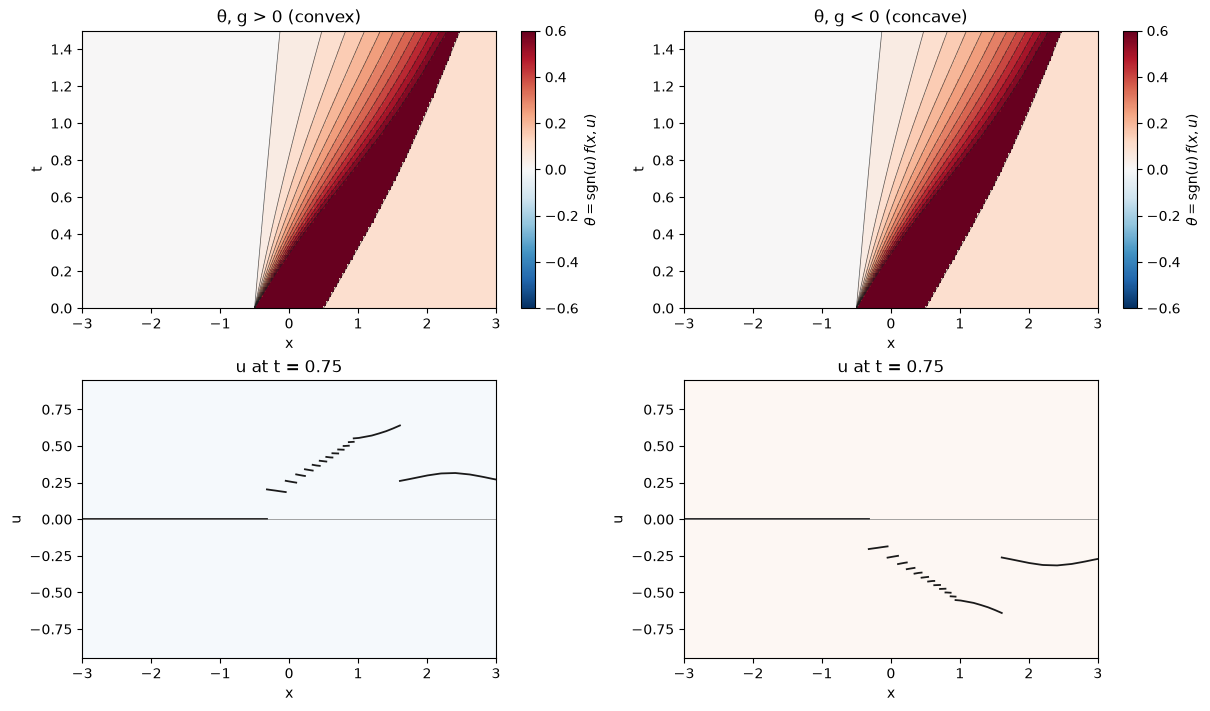

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for col, (gfun, title) in enumerate([(lambda x: 1.5 + 0.5 * np.sin(2 * x), "g > 0 (convex)"),
                                    (lambda x: -1.5 - 0.5 * np.sin(2 * x), "g < 0 (concave)")]):
    gd = PiecewiseAffine.from_function(gfun, np.linspace(-3, 3, 31))
    fl = MultiplicativeFlux(gd, 0.05)
    tr = HeteroFrontTracker(fl, [-0.5, 0.5], [0, 12, 2])   # θ: 0 -> 0.6 (fan) -> 0.1 (shock)
    h = observe_tracker(tr, np.linspace(-3, 3, 601), np.linspace(0, 1.5, 61))
    plot_spacetime(h, "theta", ax=axes[0, col])
    axes[0, col].set_title(f"θ, {title}")
    plot_profile(h, 30, "u", ax=axes[1, col])
plt.show()

## δ-fans approximate rarefactions

A fan front joining levels $k,k+1$ moves with $\kappa = s_k + s_{k+1}$.
As δ → 0 this tends to the characteristic coefficient $2s$, so the fan
fronts converge to the genuine characteristics. Those are computed exactly
by `MultiplicativeFlux.characteristic` (dotted).

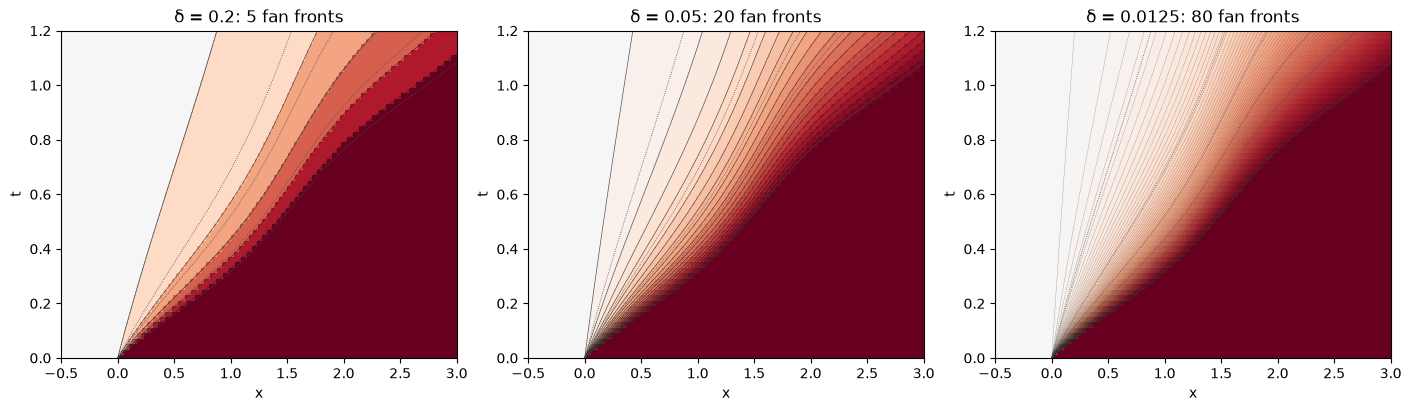

In [4]:
gd = PiecewiseAffine.from_function(lambda x: 2 + np.sin(3 * x), np.linspace(-3, 3, 41))
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, delta in zip(axes, (0.2, 0.05, 0.0125)):
    fl = MultiplicativeFlux(gd, delta)
    tr = HeteroFrontTracker.from_theta(fl, [0.0], [0.0, 1.0])
    h = observe_tracker(tr, np.linspace(-0.5, 3, 401), np.linspace(0, 1.2, 61))
    chars = [fl.characteristic(0.0, th, 1.2) for th in np.linspace(0.05, 0.95, 7)]
    plot_spacetime(h, ax=ax, characteristics=chars, colorbar=False)
    ax.set_title(f"δ = {delta}: {tr.front_count()} fan fronts")
plt.show()

Every fan front satisfies Rankine–Hugoniot for the quadratic flux, but an upward jump is not an entropy shock for that flux. Its **theta jump** is exactly δ; this is not a bound of δ on the physical state jump (which grows near zeros), nor a normed entropy-residual estimate. Refining δ approximates a rarefaction. On each open sign interval the constant-theta profiles are stationary; extending one through a zero need not satisfy the selected interface condition.